Fitted parameters:
a = 7.450541502862562e-18
b = 7.0426405193857


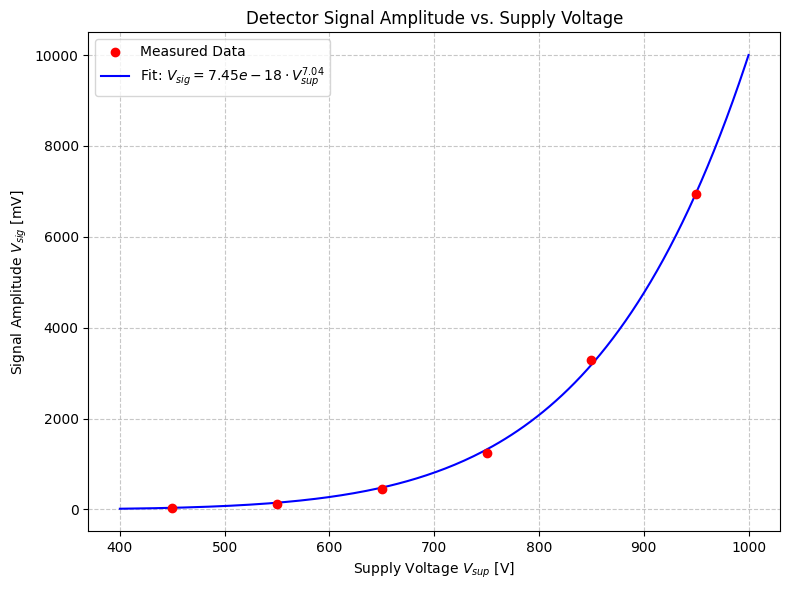

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Provided data
v_sup = np.array([450, 550, 650, 750, 850, 950], dtype=float)
v_sig = np.array([21.125, 123.250, 445.125, 1237.75, 3281.50, 6944.00], dtype=float)

# Define the power law function
def power_func(v, a, b):
    return a * (v ** b)

# Perform curve fitting
# From the lab manual (Eq. II.1.2), the exponent 'b' (alpha) is typically between 6 and 9.
# We provide an initial guess (p0) to help the optimizer.
popt, pcov = curve_fit(power_func, v_sup, v_sig, p0=[1e-20, 7.5])
a_fit, b_fit = popt

# Print the fitted parameters
print(f"Fitted parameters:")
print(f"a = {a_fit}")
print(f"b = {b_fit}")

# Create the plot
plt.figure(figsize=(8, 6))
plt.scatter(v_sup, v_sig, color='red', label='Measured Data', zorder=5)

# Generate smooth x values for the fitted curve
v_fit = np.linspace(400, 1000, 200)
plt.plot(v_fit, power_func(v_fit, a_fit, b_fit), 
         label=f'Fit: $V_{{sig}} = {a_fit:.2e} \\cdot V_{{sup}}^{{{b_fit:.2f}}}$', 
         color='blue')

plt.xlabel('Supply Voltage $V_{sup}$ [V]')
plt.ylabel('Signal Amplitude $V_{sig}$ [mV]')
plt.title('Detector Signal Amplitude vs. Supply Voltage')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('voltage_fit.png')

--- Simulated Data Points ---
Time:    50 ns  |  Voltage: -109.0 mV
Time:   150 ns  |  Voltage: -271.3 mV
Time:   300 ns  |  Voltage: -401.2 mV
Time:   560 ns  |  Voltage: -480.9 mV
Time:  1000 ns  |  Voltage: -493.5 mV
Time:  2000 ns  |  Voltage: -419.3 mV
Time:  3500 ns  |  Voltage: -312.1 mV
Time:  5600 ns  |  Voltage: -216.1 mV
Time:  8000 ns  |  Voltage: -145.6 mV
Time: 12000 ns  |  Voltage:  -67.4 mV

--- Fitted Parameters ---
K   = -596.56
RC  = 5547.39 ns
tau = 232.16 ns


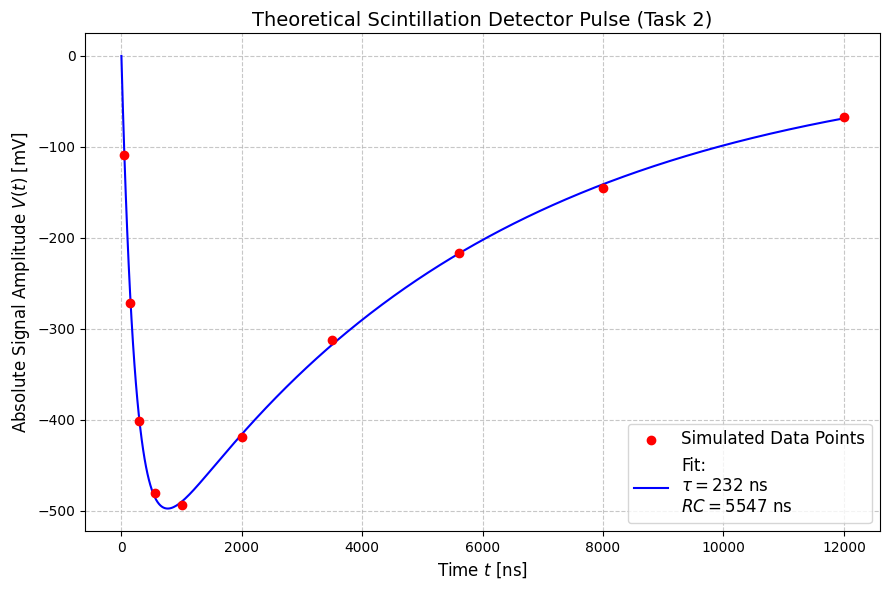

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Known parameters from your oscilloscope reading
amplitude = -500.0        # mV
t_peak = 560.0           # ns
t_decay_approx = 5600.0  # ns (approximate RC decay)

# According to the lab manual, NaI(Tl) has a time constant of approx 230 ns.
# Let's use that as our starting tau, and use t_decay_approx for RC.
tau_guess = 230.0 
rc_guess = t_decay_approx

# 2. Define the theoretical function from Eq. II.1.5
# V(t) = K * (exp(-t/RC) - exp(-t/tau))
# Where K combines the constants: K = (RC * tau / (RC - tau)) * (Q / (tau * C))
def theoretical_pulse(t, K, RC, tau):
    # Ensure no division by zero or invalid math during fitting
    if RC == tau:
        return np.zeros_like(t)
    return K * (np.exp(-t / RC) - np.exp(-t / tau))

# 3. Create a synthetic "perfect" curve to sample from
# We'll adjust K so the peak hits exactly 500 mV
t_dense = np.linspace(0, 15000, 1000)
unscaled_pulse = theoretical_pulse(t_dense, 1.0, rc_guess, tau_guess)
max_unscaled = np.max(unscaled_pulse)
K_true = amplitude / max_unscaled

# Generate 10 simulated data points to represent what you "would" have measured
t_simulated = np.array([50, 150, 300, 560, 1000, 2000, 3500, 5600, 8000, 12000])
v_simulated = theoretical_pulse(t_simulated, K_true, rc_guess, tau_guess)

# Add a tiny bit of realistic oscilloscope reading noise (optional, set scale=0 for perfect data)
np.random.seed(42)
v_simulated_noisy = v_simulated + np.random.normal(scale=5.0, size=len(v_simulated))

# 4. Perform the curve fit on the simulated data points
# We want to extract K, RC, and tau
popt, pcov = curve_fit(theoretical_pulse, t_simulated, v_simulated_noisy, p0=[K_true, rc_guess, tau_guess])
K_fit, rc_fit, tau_fit = popt

print("--- Simulated Data Points ---")
for t, v in zip(t_simulated, v_simulated_noisy):
    print(f"Time: {t:5.0f} ns  |  Voltage: {v:6.1f} mV")

print("\n--- Fitted Parameters ---")
print(f"K   = {K_fit:.2f}")
print(f"RC  = {rc_fit:.2f} ns")
print(f"tau = {tau_fit:.2f} ns")

# 5. Plotting the results
plt.figure(figsize=(9, 6))

# Plot the 10 simulated points
plt.scatter(t_simulated, v_simulated_noisy, color='red', label='Simulated Data Points', zorder=5)

# Plot the fitted curve
t_fit = np.linspace(0, max(t_simulated), 500)
plt.plot(t_fit, theoretical_pulse(t_fit, K_fit, rc_fit, tau_fit), 
         label=f'Fit:\n$\\tau = {tau_fit:.0f}$ ns\n$RC = {rc_fit:.0f}$ ns', 
         color='blue')

# Formatting
plt.xlabel('Time $t$ [ns]', fontsize=12)
plt.ylabel('Absolute Signal Amplitude $V(t)$ [mV]', fontsize=12)
plt.title('Theoretical Scintillation Detector Pulse (Task 2)', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('pulse_shape_fit.png', dpi=300)
plt.show()

--- Linear Fit Results ---
Slope (m): 50.93 mV/Gain
Intercept (c): -180.22 mV
R-squared: 0.9964


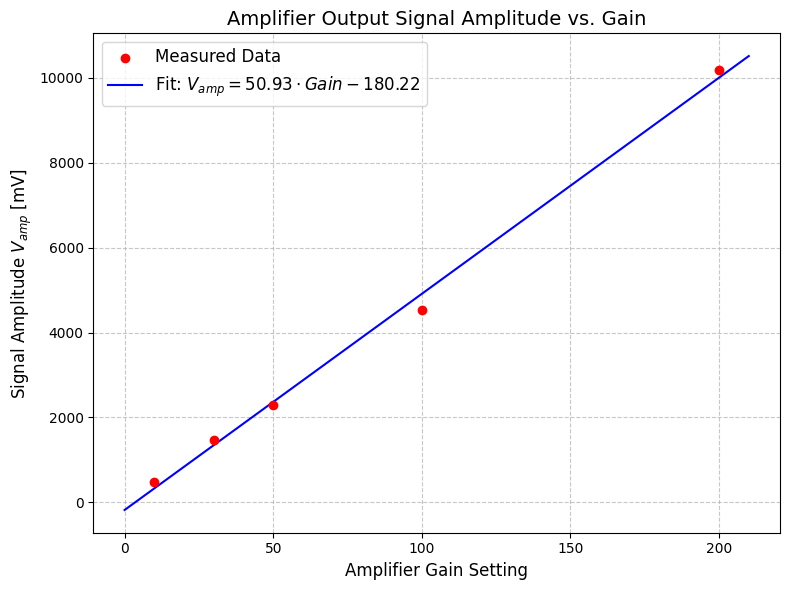

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# 1. Input the measured data
gain = np.array([10, 30, 50, 100, 200], dtype=float)
v_amp = np.array([470.00, 1472.50, 2297.50, 4535.00, 10185.0], dtype=float)

# 2. Perform linear regression
slope, intercept, r_value, p_value, std_err = linregress(gain, v_amp)

print("--- Linear Fit Results ---")
print(f"Slope (m): {slope:.2f} mV/Gain")
print(f"Intercept (c): {intercept:.2f} mV")
print(f"R-squared: {r_value**2:.4f}")

# 3. Plotting the results
plt.figure(figsize=(8, 6))

# Plot the experimental data points
plt.scatter(gain, v_amp, color='red', label='Measured Data', zorder=5)

# Plot the fitted linear line
gain_fit = np.linspace(0, 210, 100)
v_amp_fit = slope * gain_fit + intercept
plt.plot(gain_fit, v_amp_fit, 
         label=f'Fit: $V_{{amp}} = {slope:.2f} \\cdot Gain {intercept:.2f}$', 
         color='blue')

# Formatting the chart
plt.xlabel('Amplifier Gain Setting', fontsize=12)
plt.ylabel('Signal Amplitude $V_{amp}$ [mV]', fontsize=12)
plt.title('Amplifier Output Signal Amplitude vs. Gain', fontsize=14)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Show and save the plot
plt.tight_layout()
plt.show()

Peaks found: [(1400, np.int64(252), np.float64(60.0)), (1500, np.int64(565), np.float64(26.0)), (1700, np.int64(512), np.float64(16.0)), (1800, np.int64(517), np.float64(21.0))]


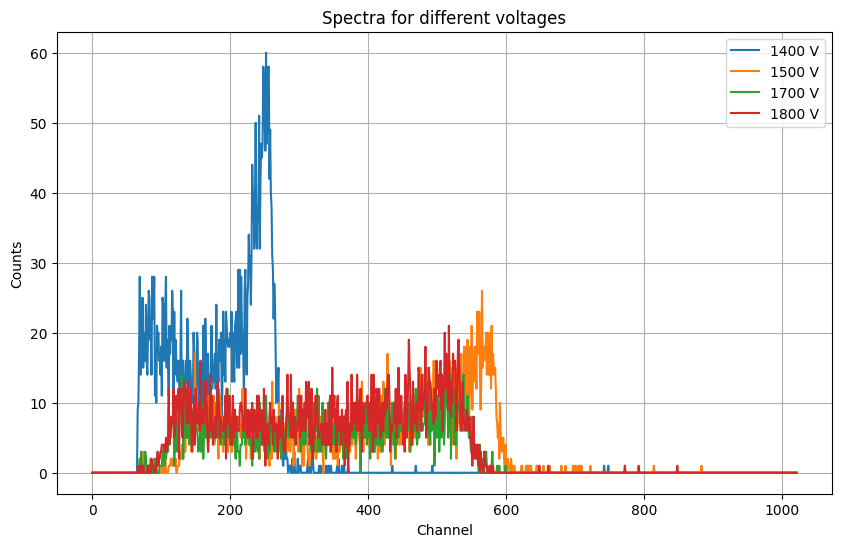

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import os

folder = 'phi_livia'  # Change this to your actual folder if needed
files = [os.path.join(folder, f) for f in ['1400.TKA', '1500.TKA', '1700.TKA', '1800.TKA']]
voltages = [1400, 1500, 1700, 1800]
peaks = []

plt.figure(figsize=(10, 6))

for f, v in zip(files, voltages):
    if os.path.exists(f):
        with open(f, 'r') as file:
            lines = file.readlines()
            # Skip first 2 lines (measurement times)
            counts = np.array([float(line.strip()) for line in lines[2:]])
            
            # The full energy peak is usually the highest peak in the upper half/third of the spectrum.
            # Let's just plot it to see.
            plt.plot(counts, label=f'{v} V')
            
            # Find peak channel (ignoring the very low channels which might be noise)
            # Let's search above channel 100
            if len(counts) > 100:
                peak_ch = np.argmax(counts[100:]) + 100
            else:
                peak_ch = np.argmax(counts)
            peaks.append((v, peak_ch, counts[peak_ch]))
            
plt.xlabel('Channel')
plt.ylabel('Counts')
plt.title('Spectra for different voltages')
plt.legend()
plt.grid(True)
plt.savefig('spectra.png')
print("Peaks found:", peaks)

   Voltage  Peak_Channel     V_amp   V_unamp
0     1400           252  2.460938  0.010254
1     1500           565  5.517578  0.022990
2     1700           512  5.000000  0.100000
3     1800           517  5.048828  0.100977


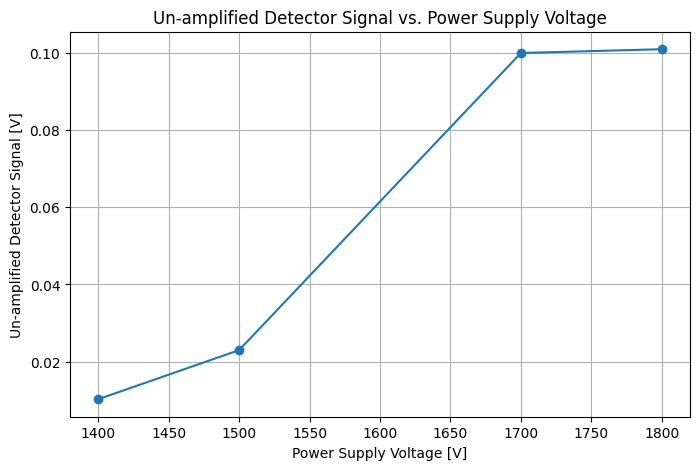

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Data provided by user
files_map = {
    'phi_livia/1400.TKA': {'v': 1400, 'gain': 240},
    'phi_livia/1500.TKA': {'v': 1500, 'gain': 240},
    'phi_livia/1700.TKA': {'v': 1700, 'gain': 50},
    'phi_livia/1800.TKA': {'v': 1800, 'gain': 50}
}

results = []

for filename, info in files_map.items():
    if os.path.exists(filename):
        with open(filename, 'r') as f:
            lines = f.readlines()
            # Omit the first two lines (measurement times)
            data = np.array([float(line.strip()) for line in lines[2:]])
            
            # Find peak channel, ignoring the very first channels where noise might be high
            # (assuming spectrum is distributed over 1024 channels)
            peak_idx = np.argmax(data[50:]) + 50
            peak_ch = peak_idx
            
            # Amplified voltage (assuming 1024 channels = 10V full range)
            v_amp = (peak_ch / 1024.0) * 10.0
            
            # Un-amplified voltage
            v_unamp = v_amp / info['gain']
            
            results.append({
                'Voltage': info['v'],
                'Peak_Channel': peak_ch,
                'V_amp': v_amp,
                'V_unamp': v_unamp
            })

# Plotting
voltages = [r['Voltage'] for r in results]
v_unamps = [r['V_unamp'] for r in results]

plt.figure(figsize=(8, 5))
plt.plot(voltages, v_unamps, marker='o', linestyle='-')
plt.xlabel('Power Supply Voltage [V]')
plt.ylabel('Un-amplified Detector Signal [V]')
plt.title('Un-amplified Detector Signal vs. Power Supply Voltage')
plt.grid(True)
plt.savefig('task2_plot.png')

import pandas as pd
df = pd.DataFrame(results)
print(df)
df.to_csv('task2_results.csv', index=False)

Losses at 20W:
SCA: 9.31%
Genie: 10.77%


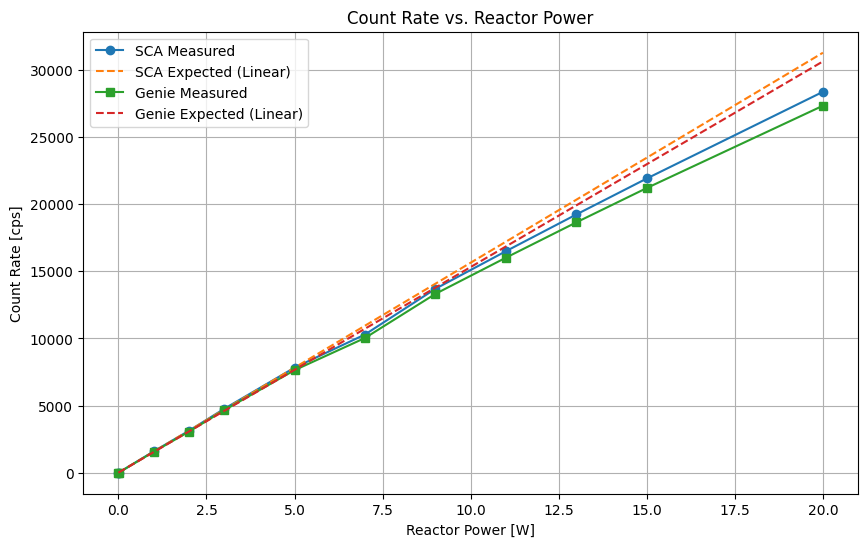

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Data
power = np.array([0, 0.004, 1, 2, 3, 5, 7, 9, 11, 13, 15, 20])
sca_counts = np.array([9, 48, 95131, 187197, 285200, 469426, 617513, 821846, 989671, 1153914, 1314640, 1701914])
genie_counts = np.array([17, 50, 93306, 183300, 278923, 458138, 601986, 799155, 960771, 1118657, 1272096, 1639811])

# Calculate count rates (m) in cps (60s measurement time)
m_sca = sca_counts / 60
m_genie = genie_counts / 60

# Linear region: 0-2W
# 0W is background, let's use 1W and 2W to establish the linear trend (or 0.004, 1, 2)
mask = (power <= 2.0)
slope_sca, intercept_sca, _, _, _ = linregress(power[mask], m_sca[mask])
slope_genie, intercept_genie, _, _, _ = linregress(power[mask], m_genie[mask])

# Expected true count rates (n) based on linearity
n_sca_expected = slope_sca * power + intercept_sca
n_genie_expected = slope_genie * power + intercept_genie

# Dead time loss estimation: loss = (n - m) / n
loss_sca = (n_sca_expected - m_sca) / n_sca_expected
loss_genie = (n_genie_expected - m_genie) / n_genie_expected

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(power, m_sca, 'o-', label='SCA Measured')
plt.plot(power, n_sca_expected, '--', label='SCA Expected (Linear)')
plt.plot(power, m_genie, 's-', label='Genie Measured')
plt.plot(power, n_genie_expected, '--', label='Genie Expected (Linear)')
plt.xlabel('Reactor Power [W]')
plt.ylabel('Count Rate [cps]')
plt.title('Count Rate vs. Reactor Power')
plt.legend()
plt.grid(True)
plt.savefig('dead_time_linearity.png')

print("Losses at 20W:")
print(f"SCA: {loss_sca[-1]*100:.2f}%")
print(f"Genie: {loss_genie[-1]*100:.2f}%")

Pulse start  : t = -0.275 µs
Peak value   : -498.49 mV  at t = 0.175 µs
Rising edge  : 450 ns
Data points  : 1651

── Fitted Parameters ──────────────────────────────
K   = -0.8389 V
RC  = 1599.8 ± 7.6 ns  (1.60 µs)
τ   = 243.3 ± 2.3 ns
R²  = 0.9923

Literature τ for NaI(Tl) ≈ 230 ns  (deviation 5.8 %)


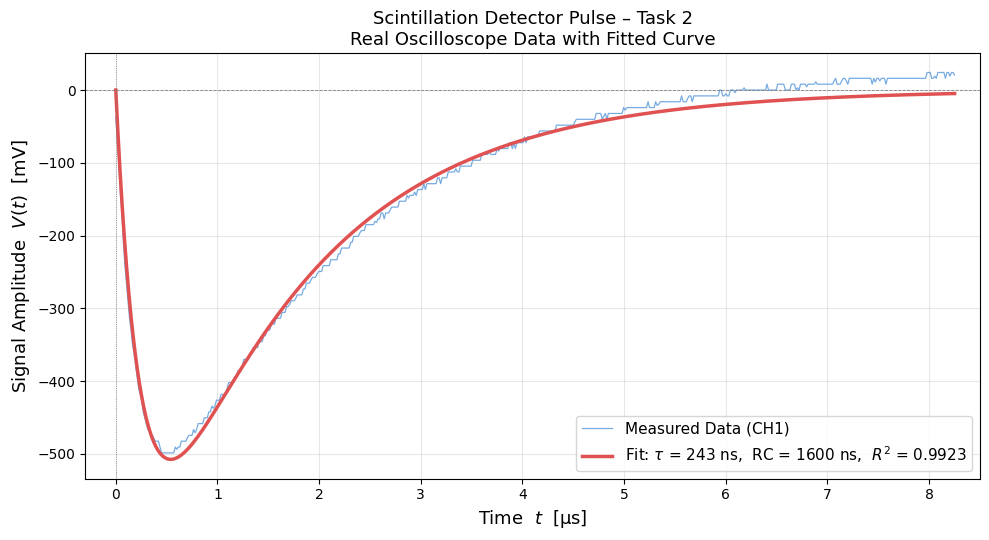


Figure saved as task2_fit.png


In [8]:
"""
Task 2 – Scintillation Detector Pulse: Real Oscilloscope Data Fit
Fits V(t) = K * (exp(-t/RC) - exp(-t/tau)) to the measured CH1 waveform.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ── 1. Load data ────────────────────────────────────────────────────────────
df = pd.read_csv("scope_0.csv", skiprows=1, header=None,
                 names=["time_s", "ch1_V", "ch2_V"])
df["time_s"] = pd.to_numeric(df["time_s"], errors="coerce")
df["ch1_V"]  = pd.to_numeric(df["ch1_V"],  errors="coerce")
df = df.dropna(subset=["time_s", "ch1_V"])

# ── 2. Baseline correction ───────────────────────────────────────────────────
# Use first 200 points (pre-pulse region) as baseline
baseline = df["ch1_V"].iloc[:200].median()
df["ch1_corr"] = df["ch1_V"] - baseline

# ── 3. Define t = 0 at pulse start ──────────────────────────────────────────
# The pulse visibly departs from baseline at ~-0.275 µs
peak_val   = df["ch1_corr"].min()
threshold  = peak_val * 0.05                          # 5 % of peak amplitude
pre_peak   = df[df["time_s"] < 0.175e-6]
t_zero     = pre_peak[pre_peak["ch1_corr"] < threshold]["time_s"].iloc[0]

# Select the pulse window: t_zero → +8 µs
pulse = df[(df["time_s"] >= t_zero) & (df["time_s"] <= 8e-6)].copy()
pulse["t_ns"] = (pulse["time_s"] - t_zero) * 1e9     # convert to ns

t_data = pulse["t_ns"].values
v_data = pulse["ch1_corr"].values

print(f"Pulse start  : t = {t_zero*1e6:.3f} µs")
print(f"Peak value   : {peak_val*1000:.2f} mV  at t = 0.175 µs")
print(f"Rising edge  : {(0.175e-6 - t_zero)*1e9:.0f} ns")
print(f"Data points  : {len(t_data)}")

# ── 4. Model ─────────────────────────────────────────────────────────────────
def scint_pulse(t, K, RC, tau):
    """V(t) = K * (exp(-t/RC) - exp(-t/tau)),  tau < RC"""
    return K * (np.exp(-t / RC) - np.exp(-t / tau))

# Initial guesses and bounds (all times in ns)
p0     = [-0.60, 2000.0, 230.0]
bounds = ([-2.0, 500.0, 50.0], [0.0, 15000.0, 800.0])

popt, pcov = curve_fit(scint_pulse, t_data, v_data,
                       p0=p0, bounds=bounds, maxfev=20_000)
K, RC, tau = popt
K_err, RC_err, tau_err = np.sqrt(np.diag(pcov))

# Goodness of fit
v_pred = scint_pulse(t_data, *popt)
ss_res = np.sum((v_data - v_pred) ** 2)
ss_tot = np.sum((v_data - v_data.mean()) ** 2)
r2     = 1.0 - ss_res / ss_tot

print(f"\n── Fitted Parameters ──────────────────────────────")
print(f"K   = {K:.4f} V")
print(f"RC  = {RC:.1f} ± {RC_err:.1f} ns  ({RC/1000:.2f} µs)")
print(f"τ   = {tau:.1f} ± {tau_err:.1f} ns")
print(f"R²  = {r2:.4f}")
print(f"\nLiterature τ for NaI(Tl) ≈ 230 ns  (deviation {abs(tau-230)/230*100:.1f} %)")

# ── 5. Plot ───────────────────────────────────────────────────────────────────
t_fit = np.linspace(0, t_data.max(), 6000)
v_fit = scint_pulse(t_fit, K, RC, tau)

fig, ax = plt.subplots(figsize=(10, 5.5))

# Measured data (downsample for clarity)
ax.plot(t_data[::3] / 1000, v_data[::3] * 1000,
        color="#4a90d9", linewidth=0.9, alpha=0.75, label="Measured Data (CH1)")

# Fitted curve
ax.plot(t_fit / 1000, v_fit * 1000,
        color="#e05252", linewidth=2.5,
        label=fr"Fit: $\tau$ = {tau:.0f} ns,  RC = {RC:.0f} ns,  $R^2$ = {r2:.4f}")

# Annotations
ax.axhline(0, color="gray", linewidth=0.6, linestyle="--")
ax.axvline(0, color="gray", linewidth=0.6, linestyle=":")

ax.set_xlabel("Time  $t$  [µs]", fontsize=13)
ax.set_ylabel("Signal Amplitude  $V(t)$  [mV]", fontsize=13)
ax.set_title("Scintillation Detector Pulse – Task 2\nReal Oscilloscope Data with Fitted Curve",
             fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_xlim(-0.3, 8.5)

plt.tight_layout()
plt.savefig("task2_fit.png", dpi=150)
plt.show()
print("\nFigure saved as task2_fit.png")

Air   spectrum : live = 39 s,  channels = 1022
Floor spectrum : live = 24 s,  channels = 1022

Theoretical Compton edge     : 477.37 keV  (ch 583.7)
Theoretical backscatter peak : 184.33 keV  (ch 225.4)

Measured photopeak (air)       : 658.6 keV
Measured photopeak (floor)     : 661.4 keV
Measured backscatter (floor)   : 198.7 keV
Measured Compton edge (air)    : 468.7 keV

Compton edge – theory vs meas  : 477.4 keV vs 468.7 keV  (diff = 8.7 keV)

── Peak Summary ──────────────────────────────────────────────────────
Feature                       Theory [keV]  Measured [keV]   Config
--------------------------------------------------------------------
Ba Kα X-ray                           32.0   ~35.2 (ch 43)     Both
Backscatter peak                     184.3           198.7    Floor
Compton edge                         477.4           468.7      Air
Photopeak (air)                      661.7           658.6      Air
Photopeak (floor)                    661.7           661.4    Floor


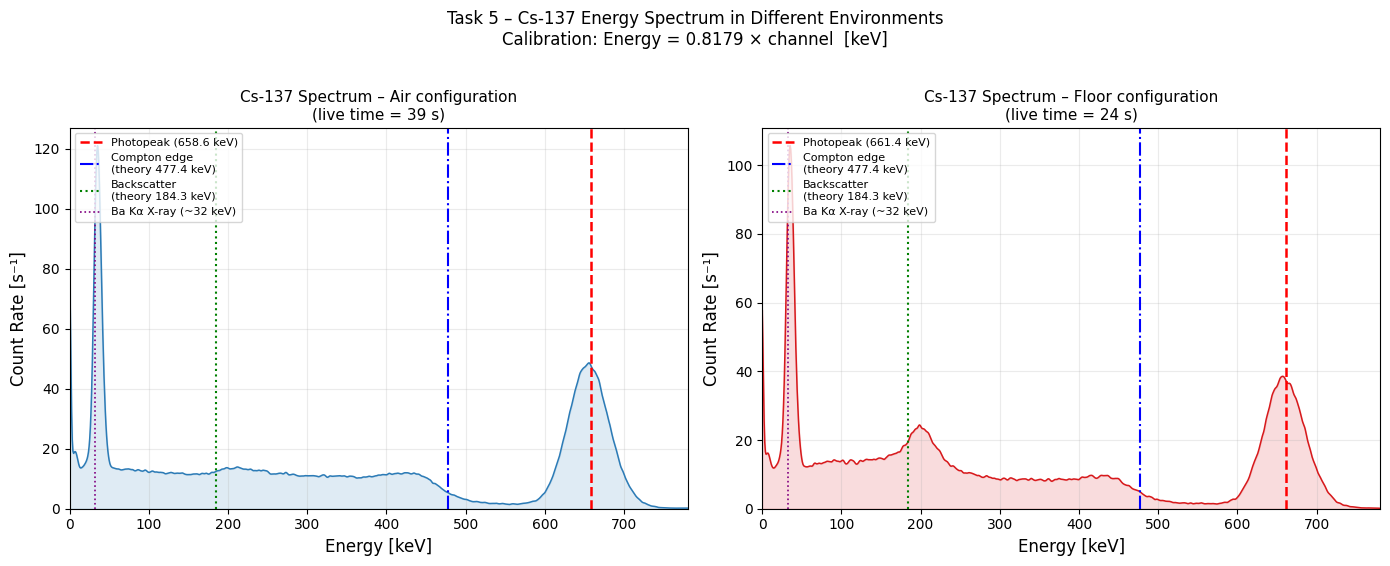


Figure saved as task5_spectra.png


In [9]:
"""
Task 5 – Cs-137 Spectrum Analysis (Lab Report)
Reads task5_air.TKA and task5_floor.TKA, applies energy calibration,
identifies all spectral features, calculates Compton edge, and plots.
"""

import numpy as np
from scipy.ndimage import gaussian_filter1d
import matplotlib.pyplot as plt

# ── 1. Read TKA files ────────────────────────────────────────────────────────
def read_tka(path):
    """Return (live_time, real_time, counts_array).
    The first two values in a .TKA file are measurement times."""
    with open(path) as f:
        vals = [float(line.strip()) for line in f if line.strip()]
    return vals[0], vals[1], np.array(vals[2:])

lt_air,   rt_air,   c_air   = read_tka("task5_air.TKA")
lt_floor, rt_floor, c_floor = read_tka("task5_floor.TKA")

print(f"Air   spectrum : live = {lt_air:.0f} s,  channels = {len(c_air)}")
print(f"Floor spectrum : live = {lt_floor:.0f} s,  channels = {len(c_floor)}")

# ── 2. Energy calibration ────────────────────────────────────────────────────
# From Task 4 Genie2000 calibration (linear, zero offset):
#   Energy [keV] = 0.8179 × channel
cal = 0.8179   # keV / channel
ch  = np.arange(len(c_air))
E   = ch * cal

# ── 3. Physics: Compton edge & backscatter peak ──────────────────────────────
E_gamma = 661.7   # keV  (Cs-137 photopeak)
m_e_c2  = 511.0   # keV  (electron rest-mass energy)

# Compton edge  (θ = 180°, maximum recoil electron energy)  Eq. I.2.2
#   E_CE = E_gamma - E_gamma / (1 + 2*E_gamma / m_e_c2)
E_scattered_180 = E_gamma / (1 + 2 * E_gamma / m_e_c2)
E_CE = E_gamma - E_scattered_180
print(f"\nTheoretical Compton edge     : {E_CE:.2f} keV  (ch {E_CE/cal:.1f})")

# Backscatter peak energy = energy of the 180°-scattered photon
E_bs = E_scattered_180
print(f"Theoretical backscatter peak : {E_bs:.2f} keV  (ch {E_bs/cal:.1f})")

# Ba Kα X-ray from Cs-137 decay: ~32 keV
E_xray = 32.0

# ── 4. Measured peak identification ──────────────────────────────────────────
# Photopeak centroid: weighted average over 620–710 keV
mask_photo = (E > 620) & (E < 710)
cent_air   = np.average(E[mask_photo], weights=c_air[mask_photo])
cent_floor = np.average(E[mask_photo], weights=c_floor[mask_photo])

# Backscatter region in floor spectrum (150–250 keV)
mask_bs      = (E > 150) & (E < 250)
idx_bs_floor = np.argmax(c_floor[mask_bs])
E_bs_meas    = E[mask_bs][idx_bs_floor]

# Compton edge: locate the steepest descent in the continuum (550–520 keV)
mask_ce  = (E > 450) & (E < 510)
grad_air = np.gradient(gaussian_filter1d(c_air.astype(float), sigma=5)[mask_ce])
idx_ce   = np.argmin(grad_air)
E_CE_meas = E[mask_ce][idx_ce]

print(f"\nMeasured photopeak (air)       : {cent_air:.1f} keV")
print(f"Measured photopeak (floor)     : {cent_floor:.1f} keV")
print(f"Measured backscatter (floor)   : {E_bs_meas:.1f} keV")
print(f"Measured Compton edge (air)    : {E_CE_meas:.1f} keV")
print(f"\nCompton edge – theory vs meas  : {E_CE:.1f} keV vs {E_CE_meas:.1f} keV"
      f"  (diff = {abs(E_CE - E_CE_meas):.1f} keV)")

# ── 5. Summary table ─────────────────────────────────────────────────────────
print("\n── Peak Summary ──────────────────────────────────────────────────────")
print(f"{'Feature':<28} {'Theory [keV]':>13} {'Measured [keV]':>15} {'Config':>8}")
print("-" * 68)
print(f"{'Ba Kα X-ray':<28} {E_xray:>13.1f} {'~35.2 (ch 43)':>15} {'Both':>8}")
print(f"{'Backscatter peak':<28} {E_bs:>13.1f} {f'{E_bs_meas:.1f}':>15} {'Floor':>8}")
print(f"{'Compton edge':<28} {E_CE:>13.1f} {f'{E_CE_meas:.1f}':>15} {'Air':>8}")
print(f"{'Photopeak (air)':<28} {E_gamma:>13.1f} {f'{cent_air:.1f}':>15} {'Air':>8}")
print(f"{'Photopeak (floor)':<28} {E_gamma:>13.1f} {f'{cent_floor:.1f}':>15} {'Floor':>8}")

# ── 6. Smooth and convert to count rate ──────────────────────────────────────
sm_air   = gaussian_filter1d(c_air.astype(float),   sigma=2)
sm_floor = gaussian_filter1d(c_floor.astype(float), sigma=2)
rate_air   = sm_air   / lt_air
rate_floor = sm_floor / lt_floor

# ── 7. Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

specs = [
    ("Air",   rate_air,   lt_air,   cent_air,   "#2c7bb6"),
    ("Floor", rate_floor, lt_floor, cent_floor, "#d7191c"),
]

for ax, (label, rate, lt, centroid, col) in zip(axes, specs):
    ax.fill_between(E, rate, alpha=0.15, color=col)
    ax.plot(E, rate, color=col, linewidth=1.1)
    ax.set_xlim(0, 780)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Energy [keV]", fontsize=12)
    ax.set_ylabel("Count Rate [s⁻¹]", fontsize=12)
    ax.set_title(f"Cs-137 Spectrum – {label} configuration\n(live time = {lt:.0f} s)",
                 fontsize=11)
    ax.grid(True, alpha=0.25)

    # Vertical marker lines
    ax.axvline(centroid, color="red",    lw=1.8, ls="--",
               label=f"Photopeak ({centroid:.1f} keV)")
    ax.axvline(E_CE,     color="blue",   lw=1.5, ls="-.",
               label=f"Compton edge\n(theory {E_CE:.1f} keV)")
    ax.axvline(E_bs,     color="green",  lw=1.5, ls=":",
               label=f"Backscatter\n(theory {E_bs:.1f} keV)")
    ax.axvline(E_xray,   color="purple", lw=1.2, ls=":",
               label=f"Ba Kα X-ray (~{E_xray:.0f} keV)")

    ax.legend(fontsize=8, loc="upper left")

plt.suptitle(
    "Task 5 – Cs-137 Energy Spectrum in Different Environments\n"
    "Calibration: Energy = 0.8179 × channel  [keV]",
    fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig("task5_spectra.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nFigure saved as task5_spectra.png")